# PeakPlan | Part 2 — Forecast model development

PeakPlan gives independent hotel managers a 12-month view of monthly market occupancy and average daily room rate (ADR). The outlook is a reference for budgeting and pricing reviews. Property-specific decisions also depend on the hotel's own bookings, inventory, and costs.

This notebook uses the LVCVA snapshot from data preparation, builds candidate forecasts for Downtown, Strip, and Las Vegas Overall, and exports them in a shared format. Part 3 will compare the candidates on historical forecasts before the team selects the app's final results.

## 1. Rebuild the monthly inputs

The local reader follows the date-header and actual-value extraction from data preparation. It selects the six target rows from the eight archived workbooks. January 2019 through September 2026 gives 93 observed months per region. Occupancy uses a fraction internally and ADR uses nominal U.S. dollars. The 2020–2021 observations are retained as published.

Use the project Python environment and run this notebook from the repository root or the notebooks directory. The loader reads the local Excel files, and the final cell writes the two CSVs used for handoff.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

# Resolve paths for both VS Code notebooks and runs launched at the repo root.
ROOT = Path.cwd().resolve()
if not (ROOT / "data/raw/lvcva").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "data/raw/lvcva").is_dir():
    raise FileNotFoundError("Open this notebook from the PeakPlan repository.")
sys.path.insert(0, str(ROOT))

In [2]:
from src.peakplan_data import DATA_CUTOFF, METRIC_UNITS, REGION_NAMES, load_monthly_targets
from src.peakplan_models import (
    HORIZON, INTERVAL_LEVEL, MODEL_SPECS, TRAINING_WINDOWS, ModelFitError,
    demand_labels, forecast, select_training_window,
)

TITLE = {"occupancy": "Occupancy", "adr": "Average daily room rate"}
REGION_COLOR = {"downtown": "#ad5c38", "strip": "#19796d", "overall": "#203a56"}
FORMAT = {"occupancy": PercentFormatter(1), "adr": StrMethodFormatter("${x:,.0f}")}

In [3]:
targets = load_monthly_targets(ROOT / "data/raw/lvcva")
history_by_region = {
    region: group.set_index("month")[list(METRIC_UNITS)].asfreq("MS")
    for region, group in targets.groupby("region", sort=False)
}
coverage = targets.groupby("region", sort=False)["month"].agg(["min", "max", "size"])
coverage.index = coverage.index.map(REGION_NAMES)
display(coverage.rename(columns={"min": "First month", "max": "Last month", "size": "Months"}))

latest = targets.loc[targets["month"].eq(DATA_CUTOFF)].set_index("region")
latest_display = latest[["occupancy", "adr"]].rename(index=REGION_NAMES).copy()
latest_display["occupancy"] = latest_display["occupancy"].map("{:.1%}".format)
latest_display["adr"] = latest_display["adr"].map("${:,.2f}".format)
display(latest_display)

,First month,Last month,Months
region,,,
Las Vegas Overall,2019-01-01,2026-09-01,93
Strip,2019-01-01,2026-09-01,93
Downtown,2019-01-01,2026-09-01,93


,occupancy,adr
region,,
Las Vegas Overall,78.1%,$178.63
Strip,80.1%,$184.63
Downtown,62.0%,$95.94


## 2. Check what the model needs to explain

The original EDA found seasonal differences between regions and a large pandemic shock. The two training policies below test whether all available history or the more recent market gives better forecasts. Both keep the same evaluation actuals. January 2022 is a practical start for the recent window. Recovery still affected parts of that window.

In the classroom ARIMA workflow, we inspected differences, ACF, and PACF before validating candidates. Here the recent Downtown window is an example. The plots and ADF tests describe the completed archive and help explain the candidate families. Part 3 will use historical training cutoffs to assess prediction accuracy.

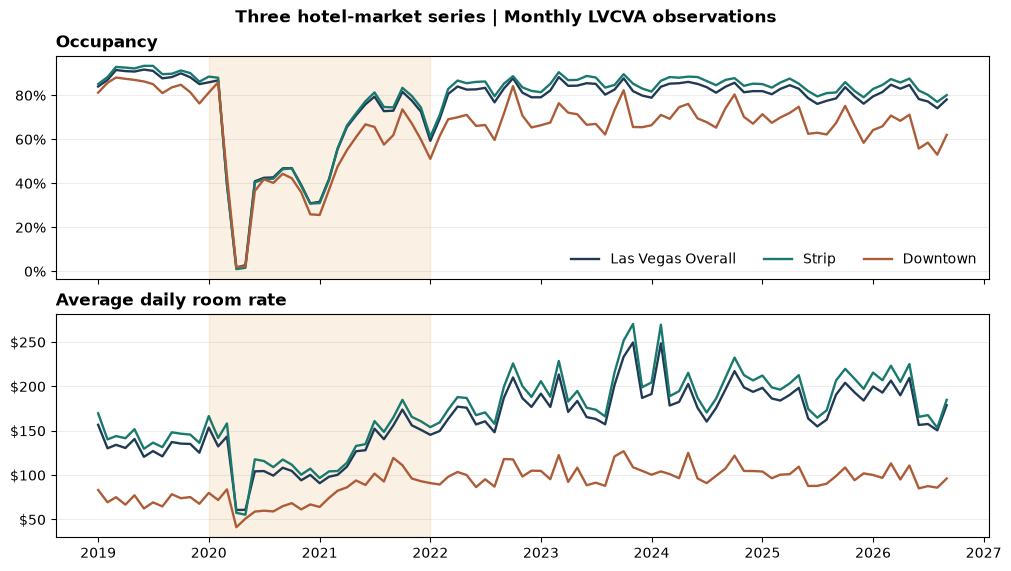

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True, layout="constrained")
for ax, metric in zip(axes, METRIC_UNITS):
    for region, history in history_by_region.items():
        ax.plot(history.index, history[metric], color=REGION_COLOR[region],
                lw=1.7, label=REGION_NAMES[region])
    ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2022-01-01"),
               color="#e9bf81", alpha=0.22)
    ax.set_title(TITLE[metric], loc="left", fontweight="bold")
    ax.yaxis.set_major_formatter(FORMAT[metric])
    ax.grid(axis="y", alpha=0.22)
axes[0].legend(frameon=False, ncol=3, loc="lower right")
fig.suptitle("Three hotel-market series | Monthly LVCVA observations", fontweight="bold")
plt.show()

In [5]:
downtown = history_by_region["downtown"]
recent = select_training_window(downtown, "since_2022")
diagnostic_series = {
    "occupancy": np.log(recent["occupancy"] / (1 - recent["occupancy"])),
    "adr": np.log(recent["adr"]),
}
adf_rows = []
for metric, series in diagnostic_series.items():
    views = {"Transformed level": series, "First difference": series.diff(),
             "Annual difference": series.diff(12)}
    for view, values in views.items():
        statistic, pvalue, lags, nobs, *_ = adfuller(values.dropna(), autolag="AIC", result_object=False)
        adf_rows.append((TITLE[metric], view, statistic, pvalue, lags, nobs))

display(pd.DataFrame(adf_rows, columns=["Target", "View", "ADF", "p-value", "Lags", "N"]).round(4))

,Target,View,ADF,p-value,Lags,N
0,Occupancy,Transformed level,1.6421,0.9980,11,45
1,Occupancy,First difference,-2.1409,0.2284,11,44
2,Occupancy,Annual difference,-2.0154,0.2799,3,41
3,Average daily room rate,Transformed level,-0.4598,0.8996,11,45
4,Average daily room rate,First difference,-3.9740,0.0016,11,44
5,Average daily room rate,Annual difference,-1.6345,0.4651,10,34


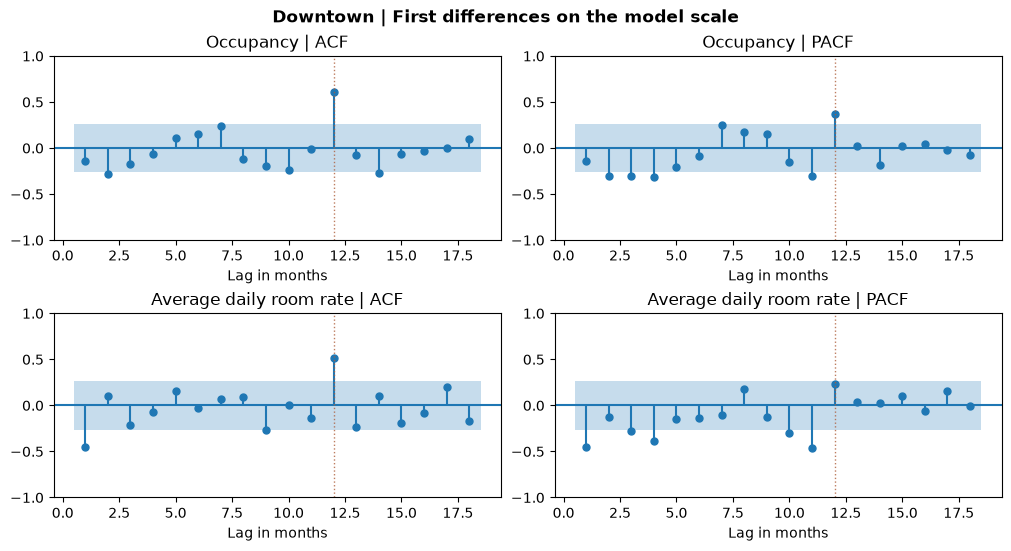

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10, 5.4), layout="constrained")
for metric, row in zip(METRIC_UNITS, axes):
    difference = diagnostic_series[metric].diff().dropna()
    plot_acf(difference, lags=18, zero=False, ax=row[0], bartlett_confint=False)
    plot_pacf(difference, lags=18, zero=False, ax=row[1], method="ywm")
    row[0].set_title(f"{TITLE[metric]} | ACF")
    row[1].set_title(f"{TITLE[metric]} | PACF")
    for ax in row:
        ax.axvline(12, color="#ad5c38", lw=1, ls=":", alpha=0.8)
        ax.set_xlabel("Lag in months")
fig.suptitle("Downtown | First differences on the model scale", fontweight="bold")
plt.show()

The ADF result for first-differenced Downtown ADR is below 0.05 in this window. The same test for occupancy does not reject a unit root, and the tests on annual differences are also inconclusive. These are reasons to keep the paired VAR exploratory. A stable fitted VAR and a convincing out-of-sample result answer different questions.

## 3. Define the forecast candidates

- **Baselines.** The same month last year is the main comparator because the app plans around the calendar. The latest observed month is a second comparator for changes in market level.
- **Class models.** The ETS candidates separate the effects of a level, annual seasonal pattern, and damped trend. A small nonseasonal ARIMA and a seasonal ARIMA test different assumptions about persistence and seasonality. These fit the Week 2–3 workflow.
- **Extensions.** Robust STL estimates seasonality while downweighting unusual observations in the decomposition. The harmonic model learns a smooth seasonal curve from calendar terms with AR(1) errors. The paired VAR tests whether past occupancy and ADR movements together are informative after annual differencing, following the Week 4 stationarity and inversion workflow.

The fixed specifications keep the search manageable with 93 months. The univariate fits use one outcome at a time. The Fourier terms depend only on calendar month, and the VAR forecasts the two targets jointly from history. Reported future visitor counts and RevPAR are unavailable when the forecast is made.

In [7]:
model_catalog = pd.DataFrame.from_dict(
    {name: vars(spec) for name, spec in MODEL_SPECS.items()}, orient="index"
)
display(model_catalog.rename_axis("Model").rename(columns={"min_months": "Minimum months"}))

window_sizes = {name: len(select_training_window(downtown, name)) for name in TRAINING_WINDOWS}
display(pd.Series(window_sizes, name="Months at September 2026 cutoff").to_frame())

,family,Minimum months,description
Model,,,
seasonal_naive,Baseline,24,Repeat the same month last year
naive,Baseline,24,Repeat the latest observation
ets_level,ETS,24,Smoothed level
ets_seasonal,ETS,24,Smoothed level and annual seasonality
ets_damped,ETS,36,Damped trend and annual seasonality
arima,ARIMA,24,"ARIMA(1,1,0)"
sarima,ARIMA,36,"SARIMA(0,1,1)(0,1,1)[12]"
robust_stl_ets,STL + ETS,36,Robust STL with a damped ETS trend
harmonic_ar,Dynamic regression,36,Annual Fourier terms with AR(1) errors


,Months at September 2026 cutoff
all_history,93
since_2022,57


Models estimate occupancy on a logit scale and ADR on a log scale, then return to business units. The inverse-transformed model centers are median-style point forecasts under symmetric model-scale errors. The two naïve points equal their historical references.

Each candidate returns a nominal **80% prediction interval**. ETS and ARIMA use fitted-model intervals. STL adds back the estimated seasonal pattern, and VAR restores the corresponding observed month from the previous year. Baseline intervals assume Gaussian innovations on the model scale. These intervals depend on their models' assumptions. Part 3 can check how often the observed values fall inside them.

## 4. Produce candidate forecasts

The last actual month is September 2026. Every candidate forecasts October 2026 to September 2027 under both training policies. A failed fit is recorded so the team can account for it in evaluation. The resulting rows are previews for development and discussion. Model choice will use Part 3's backtests.

In [8]:
def candidate_rows(region, metric, model, window, history):
    """Attach the context needed to interpret one candidate forecast."""
    train = select_training_window(history, window)
    result = forecast(train, metric, model)
    notes = result.attrs["fit_warnings"]
    previous_year = result.index - pd.DateOffset(years=1)
    result["last_year_actual"] = train[metric].reindex(previous_year).to_numpy()
    result["demand_band"] = pd.NA
    if metric == "occupancy":
        result["demand_band"] = demand_labels(result["forecast"], train["occupancy"])
    result = result.reset_index().assign(
        region=region, metric=metric, unit=METRIC_UNITS[metric],
        model=model, training_window=window, train_start=train.index[0],
        origin=train.index[-1], interval_level=INTERVAL_LEVEL,
    )
    return result, notes

In [9]:
forecast_frames, failures, fit_notes = [], [], []
for region, history in history_by_region.items():
    for metric in METRIC_UNITS:
        for window in TRAINING_WINDOWS:
            for model in MODEL_SPECS:
                keys = (region, metric, window, model)
                try:
                    rows, notes = candidate_rows(region, metric, model, window, history)
                except ModelFitError as error:
                    failures.append((*keys, str(error)))
                    continue
                forecast_frames.append(rows)
                fit_notes.extend((*keys, note) for note in notes)

candidates = pd.concat(forecast_frames, ignore_index=True)
run_keys = ["region", "metric", "training_window", "model"]
attempts = len(history_by_region) * len(METRIC_UNITS) * len(TRAINING_WINDOWS) * len(MODEL_SPECS)
print(f"{len(forecast_frames)} of {attempts} candidate fits returned a forecast.")
if failures:
    display(pd.DataFrame(failures, columns=[*run_keys, "Failure"]))
if fit_notes:
    display(pd.DataFrame(fit_notes, columns=[*run_keys, "Fit note"]))

120 of 120 candidate fits returned a forecast.


,region,metric,training_window,model,Fit note
0,overall,occupancy,since_2022,sarima,Non-invertible starting seasonal moving averag...
1,overall,adr,since_2022,sarima,Non-invertible starting seasonal moving averag...
2,strip,occupancy,since_2022,sarima,Non-invertible starting seasonal moving averag...
3,strip,adr,since_2022,sarima,Non-invertible starting seasonal moving averag...
4,downtown,occupancy,since_2022,sarima,Non-invertible starting seasonal moving averag...
5,downtown,adr,since_2022,sarima,Non-invertible starting seasonal moving averag...


In [10]:
expected_dates = pd.date_range(DATA_CUTOFF + pd.offsets.MonthBegin(), periods=HORIZON, freq="MS")
assert candidates["origin"].eq(DATA_CUTOFF).all()
assert not candidates.duplicated([*run_keys, "month"]).any()
assert all(pd.DatetimeIndex(group["month"]).equals(expected_dates)
           for _, group in candidates.groupby(run_keys))
assert candidates["lower"].le(candidates["forecast"]).all()
assert candidates["forecast"].le(candidates["upper"]).all()

# This candidate must repeat the actual value from exactly one year earlier.
seasonal_reference = candidates.loc[candidates["model"].eq("seasonal_naive")]
np.testing.assert_array_equal(seasonal_reference["forecast"], seasonal_reference["last_year_actual"])
print(f"{len(candidates):,} forecast rows | {expected_dates[0]:%b %Y}–{expected_dates[-1]:%b %Y}")

1,440 forecast rows | Oct 2026–Sep 2027


## 5. Inspect the forecasts in product terms

The example below shows Downtown with selected candidates from different families. The chart compares the shapes and levels the app might display. The methods can disagree on how quickly recent market changes fade. That disagreement is one reason to compare both strategies in the rolling backtest.

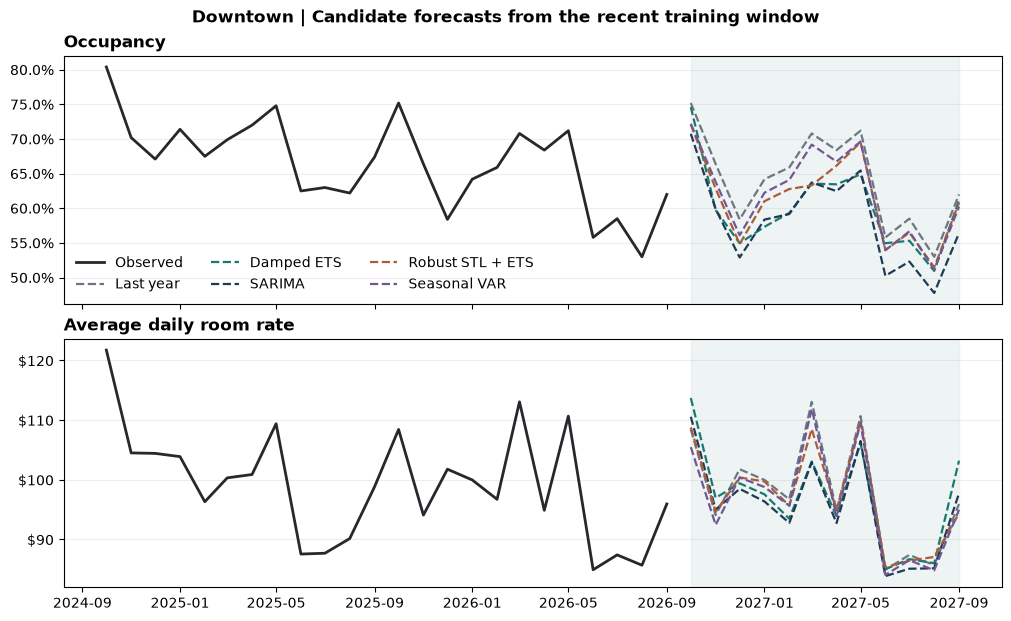

In [11]:
display_models = {
    "seasonal_naive": ("Last year", "#6c7782"),
    "ets_damped": ("Damped ETS", "#19796d"),
    "sarima": ("SARIMA", "#203a56"),
    "robust_stl_ets": ("Robust STL + ETS", "#ad5c38"),
    "seasonal_var": ("Seasonal VAR", "#725795"),
}
fig, axes = plt.subplots(2, 1, figsize=(10, 6.1), sharex=True, layout="constrained")
for ax, metric in zip(axes, METRIC_UNITS):
    actual = downtown[metric].tail(24)
    ax.plot(actual.index, actual, color="#25282c", lw=2, label="Observed")
    preview = candidates.query("region == 'downtown' and training_window == 'since_2022'")
    for model, (label, color) in display_models.items():
        line = preview.loc[preview["metric"].eq(metric) & preview["model"].eq(model)]
        ax.plot(line["month"], line["forecast"], color=color, ls="--", lw=1.6, label=label)
    ax.axvspan(expected_dates[0], expected_dates[-1], color="#e3eceb", alpha=0.6)
    ax.set_title(TITLE[metric], loc="left", fontweight="bold")
    ax.yaxis.set_major_formatter(FORMAT[metric])
    ax.grid(axis="y", alpha=0.22)
axes[0].legend(frameon=False, ncol=3)
fig.suptitle("Downtown | Candidate forecasts from the recent training window", fontweight="bold")
plt.show()

In [12]:
mean_by_window = (
    candidates.query("region == 'downtown' and model in ['ets_damped', 'sarima', 'robust_stl_ets']")
    .groupby(["metric", "model", "training_window"])["forecast"].mean().unstack()
)
units = mean_by_window.index.get_level_values("metric").map({"occupancy": 100, "adr": 1})
mean_by_window = mean_by_window.mul(units.to_numpy(), axis=0)
mean_by_window["Recent minus all"] = mean_by_window["since_2022"] - mean_by_window["all_history"]
display(mean_by_window.rename(index={"occupancy": "Occupancy (%)", "adr": "ADR (USD)"}).round(2))

training_window               all_history  since_2022  Recent minus all
metric        model                                                    
ADR (USD)     ets_damped            90.32       97.10              6.78
              robust_stl_ets        97.59       97.13             -0.46
              sarima                91.77       95.60              3.82
Occupancy (%) ets_damped            57.82       60.02              2.20
              robust_stl_ets        61.91       61.28             -0.63
              sarima                61.60       58.29             -3.31

The training decision changes the preview in different directions. For damped ETS, using the recent window raises average Downtown occupancy by 2.20 points and average ADR by $6.78. For SARIMA, the recent window lowers average occupancy by 3.31 points while raising ADR by $3.82. Neither comparison measures accuracy. The same historical forecast origins will let us test which policy holds up.

### Example calendar values

The following is one candidate, chosen to show the data format. The calendar can show forecast occupancy, a prediction range and the observed value for the same month last year. Labels use the 33rd and 67th percentiles of the most recent 36 observed occupancy values in that region. They describe demand relative to that market's recent history. A label near a threshold can change when the forecast or its uncertainty changes.

ADR is the predicted market rate. For the prototype's what-if calculation, the user supplies a property rate and room count. Monthly room revenue under a fixed-occupancy assumption is rooms × days × occupancy × user-entered ADR. That scenario and the forecast should retain their own labels in the product.

In [13]:
calendar_view = (
    candidates.query("region == 'downtown' and model == 'ets_damped' "
                     "and training_window == 'since_2022' and metric == 'occupancy'")
    .set_index("month")[["forecast", "lower", "upper", "last_year_actual", "demand_band"]]
)
for column in ["forecast", "lower", "upper", "last_year_actual"]:
    calendar_view[column] = calendar_view[column].map("{:.1%}".format)
calendar_view.index = calendar_view.index.strftime("%b %Y")
display(calendar_view)

,forecast,lower,upper,last_year_actual,demand_band
month,,,,,
Oct 2026,74.6%,71.8%,77.2%,75.2%,busy
Nov 2026,59.7%,56.1%,63.3%,66.4%,slow
Dec 2026,55.0%,51.1%,58.8%,58.4%,slow
Jan 2027,57.3%,53.2%,61.3%,64.2%,slow
Feb 2027,59.3%,55.0%,63.5%,65.9%,slow
Mar 2027,63.6%,59.1%,67.8%,70.8%,slow
Apr 2027,63.5%,58.7%,67.9%,68.4%,slow
May 2027,64.9%,60.0%,69.5%,71.2%,slow
Jun 2027,55.0%,49.4%,60.4%,55.8%,slow


The example assigns October a busy label and the other 11 months a slow label. This reflects how the candidate compares with recent Downtown history. An outlook can distinguish weaker-than-usual months from the busiest months within the forecast year. Those are two different views of demand and would need clearly different labels in the interface.

## 6. Hand off to evaluation and the interface

The shared model function accepts an already-sliced training frame. The evaluation notebook can call it at earlier origins with the same horizon, then join predictions to the held-out monthly actuals. Use percentage points for absolute occupancy error and dollars for absolute ADR error. Evaluate both windows on matching origins and report failures as part of the comparison.

The exported candidate table includes region, metric, model, window, origin, month, point estimate, bounds, interval level, prior-year actual and a demand label for occupancy. The app will use the selected forecasts after evaluation. See [the modeling handoff](../docs/modeling_handoff.md) for the suggested fold dates, schemas, and integration plan.

In [14]:
output_columns = [
    "region", "metric", "unit", "model", "training_window", "train_start",
    "origin", "month", "horizon", "forecast", "lower", "upper", "interval_level",
    "last_year_actual", "demand_band",
]
targets_path = ROOT / "data/processed/monthly_targets.csv"
candidates_path = ROOT / "outputs/forecasts/candidate_forecasts.csv"

targets_path.parent.mkdir(parents=True, exist_ok=True)
candidates_path.parent.mkdir(parents=True, exist_ok=True)
targets.to_csv(targets_path, index=False, date_format="%Y-%m-%d")
candidates[output_columns].to_csv(candidates_path, index=False, date_format="%Y-%m-%d")

for path in (targets_path, candidates_path):
    print(path.relative_to(ROOT))

data/processed/monthly_targets.csv
outputs/forecasts/candidate_forecasts.csv


## References

- Course Weeks 1–4. Forecast definition and validation, ETS, differencing and ARIMA diagnostics, and multivariate VAR.
- [LVCVA Research Center](https://www.lvcva.com/research/) and [data preparation and exploration](01_data_preparation.ipynb).
- [statsmodels ETS examples](https://www.statsmodels.org/stable/examples/notebooks/generated/ets.html), [STL forecasting](https://www.statsmodels.org/stable/generated/statsmodels.tsa.forecasting.stl.STLForecast.html), and [dynamic harmonic regression](https://otexts.com/fpp3/dhr.html).
- [Chronos research paper](https://arxiv.org/abs/2403.07815). A pretrained forecasting model is a possible separate benchmark. The current candidates can all run on the team's existing Python setup.